<a href="https://colab.research.google.com/github/leandroxxxxx/lowres-plate-char-classification/blob/main/lowres-plate-char-classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Donwload arquivos Drive

In [1]:
manifest_drive_id = "1MDNgZVubmLU0yAiHGpsxETK9B2EwvO8E"
manifest_output = "manifest.csv"

dataset_drive_id = "1VA0xY422FFmq-YDzMHXevH0qLA2sB34Y"
dataset_output = "img.zip"

In [2]:
%%capture
import gdown

gdown.download(
    id=manifest_drive_id,
    output=manifest_output,
    quiet=False
)

gdown.download(
    id=dataset_drive_id,
    output=dataset_output,
    quiet=False
)

## 1 Environment

In [3]:
import json
import os
import random
import time
import zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import models


def set_seed(seed: int) -> None:
    """Seed every random number generator used in the notebook."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(
    f"torch {torch.__version__} | torchvision {torchvision.__version__} | "
    f"opencv {cv2.__version__} | pandas {pd.__version__}"
)
print(f"Device: {DEVICE}")
if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {props.name} | {props.total_memory / 1024**3:.1f} GB")
else:
    print("WARNING: no GPU found. In Colab: Runtime > Change runtime type > GPU.")

torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | opencv 4.14.0 | pandas 2.2.3
Device: cuda
GPU: Tesla T4 | 14.6 GB


## 2 - Configuration

In [4]:

# %%
# ---------------------------------------------------------------
# Reproducibility
# ---------------------------------------------------------------
SEED = 42

# ---------------------------------------------------------------
# Paths (files downloaded by the gdown cell land in /content)
# ---------------------------------------------------------------
WORK_DIR = Path("/content")
MANIFEST_PATH = WORK_DIR / "manifest.csv"
ZIP_PATH = WORK_DIR / "img.zip"
EXTRACT_DIR = WORK_DIR                  # the zip already contains the "img" folder
IMG_DIR = EXTRACT_DIR / "img"
OUTPUT_DIR = WORK_DIR / "outputs"       # checkpoints, split CSV, results

# ---------------------------------------------------------------
# Classes
# ---------------------------------------------------------------
LETTERS = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")
DIGITS = list("0123456789")
ALL_CLASSES = LETTERS + DIGITS          # indices 0-25 = A-Z, 26-35 = 0-9
CLASS_TO_IDX = {c: i for i, c in enumerate(ALL_CLASSES)}
NUM_CLASSES = len(ALL_CLASSES)          # 36 outputs, fixed so rare classes can be added later

# Dropped from training because they have too few samples.
# Classes with no samples at all (e.g. "M") are detected from the manifest in Cell 6.
EXCLUDED_LABELS = ["Z", "K", "X", "W", "L"]

# ---------------------------------------------------------------
# Input size (crops are 9:16, width:height)
# ---------------------------------------------------------------
INPUT_PRESETS = {"small": (36, 64), "large": (45, 80)}  # (width, height)
INPUT_PRESET = "small"
INPUT_W, INPUT_H = INPUT_PRESETS[INPUT_PRESET]

# ---------------------------------------------------------------
# Split (random, stratified by label; no group separation in this version)
# ---------------------------------------------------------------
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15
assert abs(TRAIN_FRAC + VAL_FRAC + TEST_FRAC - 1.0) < 1e-9

# ---------------------------------------------------------------
# Training
# ---------------------------------------------------------------
BATCH_SIZE = 64
EPOCHS = 30
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-2
SCHEDULER = "cosine"                    # "cosine" or "onecycle"
EARLY_STOP_PATIENCE = 8                 # epochs without val improvement; None disables
NUM_WORKERS = 0                         # images are cached in RAM, workers only add overhead

# ---------------------------------------------------------------
# Switches
# ---------------------------------------------------------------
USE_PRETRAINED = True                   # ImageNet weights for the ResNet18
USE_AMP = True                          # mixed precision, only effective on CUDA
USE_CLASS_WEIGHTS = False               # round 1 runs without class weights

USE_AMP = USE_AMP and DEVICE.type == "cuda"

# ---------------------------------------------------------------
# Setup
# ---------------------------------------------------------------
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
set_seed(SEED)

print(f"Seed: {SEED}")
print(f"Manifest: {MANIFEST_PATH} (exists: {MANIFEST_PATH.exists()})")
print(f"Zip: {ZIP_PATH} (exists: {ZIP_PATH.exists()})")
print(f"Images dir: {IMG_DIR}")
print(f"Outputs dir: {OUTPUT_DIR}")
print(f"Input size (W x H): {INPUT_W} x {INPUT_H} [{INPUT_PRESET}]")
print(f"Split train/val/test: {TRAIN_FRAC}/{VAL_FRAC}/{TEST_FRAC}")
print(
    f"Batch {BATCH_SIZE} | epochs {EPOCHS} | lr {LEARNING_RATE} | "
    f"wd {WEIGHT_DECAY} | scheduler {SCHEDULER} | patience {EARLY_STOP_PATIENCE}"
)
print(
    f"Pretrained: {USE_PRETRAINED} | AMP: {USE_AMP} | "
    f"Class weights: {USE_CLASS_WEIGHTS}"
)
print(f"Excluded labels: {EXCLUDED_LABELS}")


Seed: 42
Manifest: /content/manifest.csv (exists: True)
Zip: /content/img.zip (exists: True)
Images dir: /content/img
Outputs dir: /content/outputs
Input size (W x H): 36 x 64 [small]
Split train/val/test: 0.7/0.15/0.15
Batch 64 | epochs 30 | lr 0.0003 | wd 0.01 | scheduler cosine | patience 8
Pretrained: True | AMP: True | Class weights: False
Excluded labels: ['Z', 'K', 'X', 'W', 'L']


## 3 - Extract the dataset

In [5]:
# %%
import shutil
from collections import Counter

# Set to True to force a fresh extraction even if the images are already there.
FORCE_EXTRACT = False

# ---------------------------------------------------------------
# 1) Preconditions
# ---------------------------------------------------------------
# The gdown cell (before Cell 1) must have run first. Failing early with a clear
# message is much better than a cryptic error three cells later.
if not MANIFEST_PATH.exists():
    raise FileNotFoundError(
        f"{MANIFEST_PATH} not found. Run the gdown download cell first."
    )

# ---------------------------------------------------------------
# 2) Extract to the Colab *local* disk
# ---------------------------------------------------------------

already_extracted = IMG_DIR.exists() and any(IMG_DIR.rglob("*.png"))

if already_extracted and not FORCE_EXTRACT:
    print(f"Images already extracted in {IMG_DIR}, skipping extraction.")
else:
    if not ZIP_PATH.exists():
        raise FileNotFoundError(
            f"{ZIP_PATH} not found. Run the gdown download cell first."
        )
    t0 = time.time()
    with zipfile.ZipFile(ZIP_PATH) as zf:
        members = zf.namelist()
        print(f"Zip has {len(members)} entries. First ones: {members[:3]}")
        # extractall recreates the folder structure stored inside the zip, so with
        # EXTRACT_DIR = /content we expect to end up with /content/img/...
        zf.extractall(EXTRACT_DIR)
    print(f"Extracted in {time.time() - t0:.1f}s")

# ---------------------------------------------------------------
# 3) Verify the layout
# ---------------------------------------------------------------

if not IMG_DIR.exists():
    found = sorted(p.name for p in EXTRACT_DIR.iterdir())
    raise FileNotFoundError(
        f"Expected folder {IMG_DIR} after extraction. "
        f"Contents of {EXTRACT_DIR}: {found}. "
        "Adjust IMG_DIR (Cell 2) to match the zip structure."
    )

files = [p for p in IMG_DIR.rglob("*") if p.is_file()]

# Count files by extension: catches stray files (Thumbs.db, .DS_Store, etc.)
# and confirms that the images really are PNGs.
suffix_counts = Counter(p.suffix.lower() for p in files)
n_png = suffix_counts.get(".png", 0)
assert n_png > 0, f"No PNG files found under {IMG_DIR}. Extensions found: {dict(suffix_counts)}"

# Are the PNGs directly inside img/ or in subfolders? Cell 4 needs this to rebuild
# the full path of each image from the manifest "path" column.
subfolders = sorted({str(p.parent.relative_to(IMG_DIR)) for p in files})
size_mb = sum(p.stat().st_size for p in files) / 1024**2
free_gb = shutil.disk_usage(WORK_DIR).free / 1024**3

print(f"\nFiles by extension: {dict(suffix_counts)}")
print(f"PNG files: {n_png} | total size: {size_mb:.1f} MB | free disk: {free_gb:.1f} GB")
print(f"Subfolders under img/ ('.' means files sit directly in img/): {subfolders[:5]}")
print("Sample files:")
for p in sorted(files)[:3]:
    print("  ", p.relative_to(EXTRACT_DIR))

Zip has 5554 entries. First ones: ['img/', 'img/261022215621_759590_0001_AVI3788.avi_00-00-03.400_l_n_red1c71_1_r.png', 'img/261022215621_760496_0001_AVI3788.avi_00-00-03.400_l_n_red1c71_2_e.png']
Extracted in 0.9s

Files by extension: {'.png': 5553}
PNG files: 5553 | total size: 1.3 MB | free disk: 235.5 GB
Subfolders under img/ ('.' means files sit directly in img/): ['.']
Sample files:
   img/261022215621_759590_0001_AVI3788.avi_00-00-03.400_l_n_red1c71_1_r.png
   img/261022215621_760496_0001_AVI3788.avi_00-00-03.400_l_n_red1c71_2_e.png
   img/261022215621_760977_0001_AVI3788.avi_00-00-03.400_l_n_red1c71_3_d.png


## 4 - Load and filter the manifest

Rows in manifest: 5553
Rows whose image was not found: 0
Images on disk with no manifest row: 0

char_type vs label kind (rows: char_type, columns: is_letter):
is_letter  False  True 
char_type              
digit       2394      0
letter         0   3159
OK: each char_type value maps to a single kind (letter or digit).

Removing 124 rows of excluded classes:
label
Z    34
K    33
X    22
W    22
L    13

Final dataset: 5429 crops | 30 classes (20 letters + 10 digits) | 27 groups
Samples per class: min 61 (U) | max 533 (1) | ratio 9x


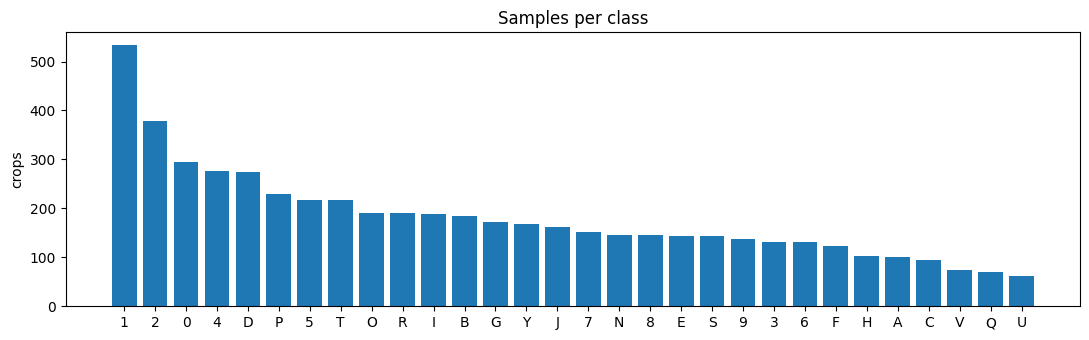

,crop_id,path,label,char_type,position,plate_text,source_stem,video_name,frame_time_s,group_id,frame_index,orig_h,orig_w,lighting,brightness,file_name,img_path,is_letter
0,261022215621_759590,261022215621_759590_0001_AVI3788.avi_00-00-03....,R,letter,1,RED1C71,0001_AVI3788.avi_00-00-03.400,AVI3788.avi,3.4,AVI3788.avi_RED1C71,16,14,8,light,normal,261022215621_759590_0001_AVI3788.avi_00-00-03....,/content/img/261022215621_759590_0001_AVI3788....,True
1,261022215621_760496,261022215621_760496_0001_AVI3788.avi_00-00-03....,E,letter,2,RED1C71,0001_AVI3788.avi_00-00-03.400,AVI3788.avi,3.4,AVI3788.avi_RED1C71,16,14,8,light,normal,261022215621_760496_0001_AVI3788.avi_00-00-03....,/content/img/261022215621_760496_0001_AVI3788....,True
2,261022215621_760977,261022215621_760977_0001_AVI3788.avi_00-00-03....,D,letter,3,RED1C71,0001_AVI3788.avi_00-00-03.400,AVI3788.avi,3.4,AVI3788.avi_RED1C71,16,14,8,light,normal,261022215621_760977_0001_AVI3788.avi_00-00-03....,/content/img/261022215621_760977_0001_AVI3788....,True


In [6]:
# ---------------------------------------------------------------
# 1) Load the manifest
# ---------------------------------------------------------------
# dtype=str on the text columns is defensive: labels such as "0" or "1" must stay
# strings. If pandas ever guessed "integer" for them, "A" would break and "01"
# would silently become 1.
df = pd.read_csv(
    MANIFEST_PATH,
    dtype={"label": str, "plate_text": str, "group_id": str, "char_type": str},
)
print(f"Rows in manifest: {len(df)}")

expected_cols = [
    "crop_id", "path", "label", "char_type", "position", "plate_text",
    "source_stem", "group_id", "frame_index", "orig_h", "orig_w",
]
missing_cols = [c for c in expected_cols if c not in df.columns]
assert not missing_cols, f"Manifest is missing columns: {missing_cols}"

# Null values would break things later (e.g. orig_h is used for quantiles).
n_nulls = int(df[expected_cols].isna().sum().sum())
assert n_nulls == 0, f"Manifest has {n_nulls} null values in the key columns"
assert df["crop_id"].is_unique, "crop_id is not unique"

# ---------------------------------------------------------------
# 2) Clean and validate the labels
# ---------------------------------------------------------------
df["label"] = df["label"].str.strip().str.upper()
unknown_labels = set(df["label"]) - set(ALL_CLASSES)
assert not unknown_labels, f"Labels outside A-Z / 0-9: {unknown_labels}"

# ---------------------------------------------------------------
# 3) Resolve the image paths
# ---------------------------------------------------------------
# The "path" column was written on Windows, so it may hold backslashes, an absolute
# path like D:\...\img\x.png, or just a file name. Instead of guessing how to patch
# that string, we keep only the FILE NAME and look it up in the folder we actually
# extracted. This works no matter what the original path looked like.
files_on_disk = sorted(IMG_DIR.rglob("*.png"))
name_to_path = {p.name: str(p) for p in files_on_disk}
assert len(name_to_path) == len(files_on_disk), (
    "Duplicate file names across subfolders: matching by file name would be ambiguous"
)

df["file_name"] = df["path"].str.replace("\\", "/", regex=False).str.split("/").str[-1]
df["img_path"] = df["file_name"].map(name_to_path)  # NaN when the file is not on disk

# Two-way check: manifest rows without an image, and images without a manifest row.
missing_files = df["img_path"].isna()
orphan_files = set(name_to_path) - set(df["file_name"])
print(f"Rows whose image was not found: {int(missing_files.sum())}")
print(f"Images on disk with no manifest row: {len(orphan_files)}")
if missing_files.any():
    print("Examples of missing files:", df.loc[missing_files, "file_name"].head(5).tolist())
    df = df[~missing_files]  # keep going without them, but we have been warned

# ---------------------------------------------------------------
# 4) Is char_type consistent with the label?
# ---------------------------------------------------------------
# char_type was typed by the operator, the label comes from the plate text. They must
# agree: every letter label should have one char_type value and every digit label the
# other. We do not assume what the values are called; the crosstab shows them.
df["is_letter"] = df["label"].str.isalpha()
print("\nchar_type vs label kind (rows: char_type, columns: is_letter):")
print(pd.crosstab(df["char_type"], df["is_letter"]).to_string())
types_per_kind = df.groupby("char_type")["is_letter"].nunique()
if (types_per_kind > 1).any():
    print("WARNING: some char_type values mix letters and digits. Check the manifest.")
else:
    print("OK: each char_type value maps to a single kind (letter or digit).")

# ---------------------------------------------------------------
# 5) Drop the excluded classes
# ---------------------------------------------------------------
excluded_mask = df["label"].isin(EXCLUDED_LABELS)
print(f"\nRemoving {int(excluded_mask.sum())} rows of excluded classes:")
print(df.loc[excluded_mask, "label"].value_counts().to_string())

# reset_index matters: later cells select rows by position (splits, DataLoaders).
# A leftover gap in the index is a classic source of off-by-one mistakes.
df = df[~excluded_mask].reset_index(drop=True)

# ---------------------------------------------------------------
# 6) Final overview
# ---------------------------------------------------------------
counts = df["label"].value_counts()
n_letters = int(df.loc[df["is_letter"], "label"].nunique())
n_digits = int(df.loc[~df["is_letter"], "label"].nunique())
print(f"\nFinal dataset: {len(df)} crops | {df['label'].nunique()} classes "
      f"({n_letters} letters + {n_digits} digits) | {df['group_id'].nunique()} groups")
print(f"Samples per class: min {counts.min()} ({counts.idxmin()}) | "
      f"max {counts.max()} ({counts.idxmax()}) | ratio {counts.max() / counts.min():.0f}x")

# Seeing the imbalance is the first step to deciding how to handle it later.
plt.figure(figsize=(11, 3.5))
plt.bar(counts.index, counts.values)
plt.title("Samples per class")
plt.ylabel("crops")
plt.tight_layout()
plt.show()

df.head(3)

## 5 - Dataset inspection

PNG modes:
png_mode
RGB    5429

PNGs whose size differs from the manifest: 0 of 5429 (0.0%)
Most common PNG sizes (w, h):
png_w  png_h
5      9        719
6      10       567
       11       475
5      10       427
4      8        423

Aspect ratio w/h (expected 0.5625):
count    5429.0000
mean        0.5623
std         0.0500
min         0.4286
25%         0.5333
50%         0.5556
75%         0.6000
max         0.7143
Crops more than 5% away from 9:16: 2813

orig_h quantiles:
0.00     5.0
0.10     7.0
0.25     8.0
0.50    10.0
0.75    12.0
0.90    15.0
1.00    21.0
Candidate 4-band edges (quartiles of orig_h): [8.0, 10.0, 12.0]
Crops upscaled to INPUT_H=64: 100.0% | downscaled: 0.0%


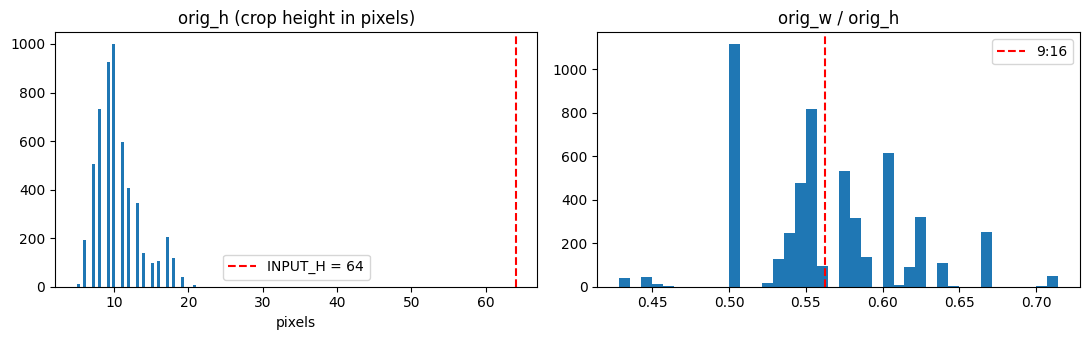

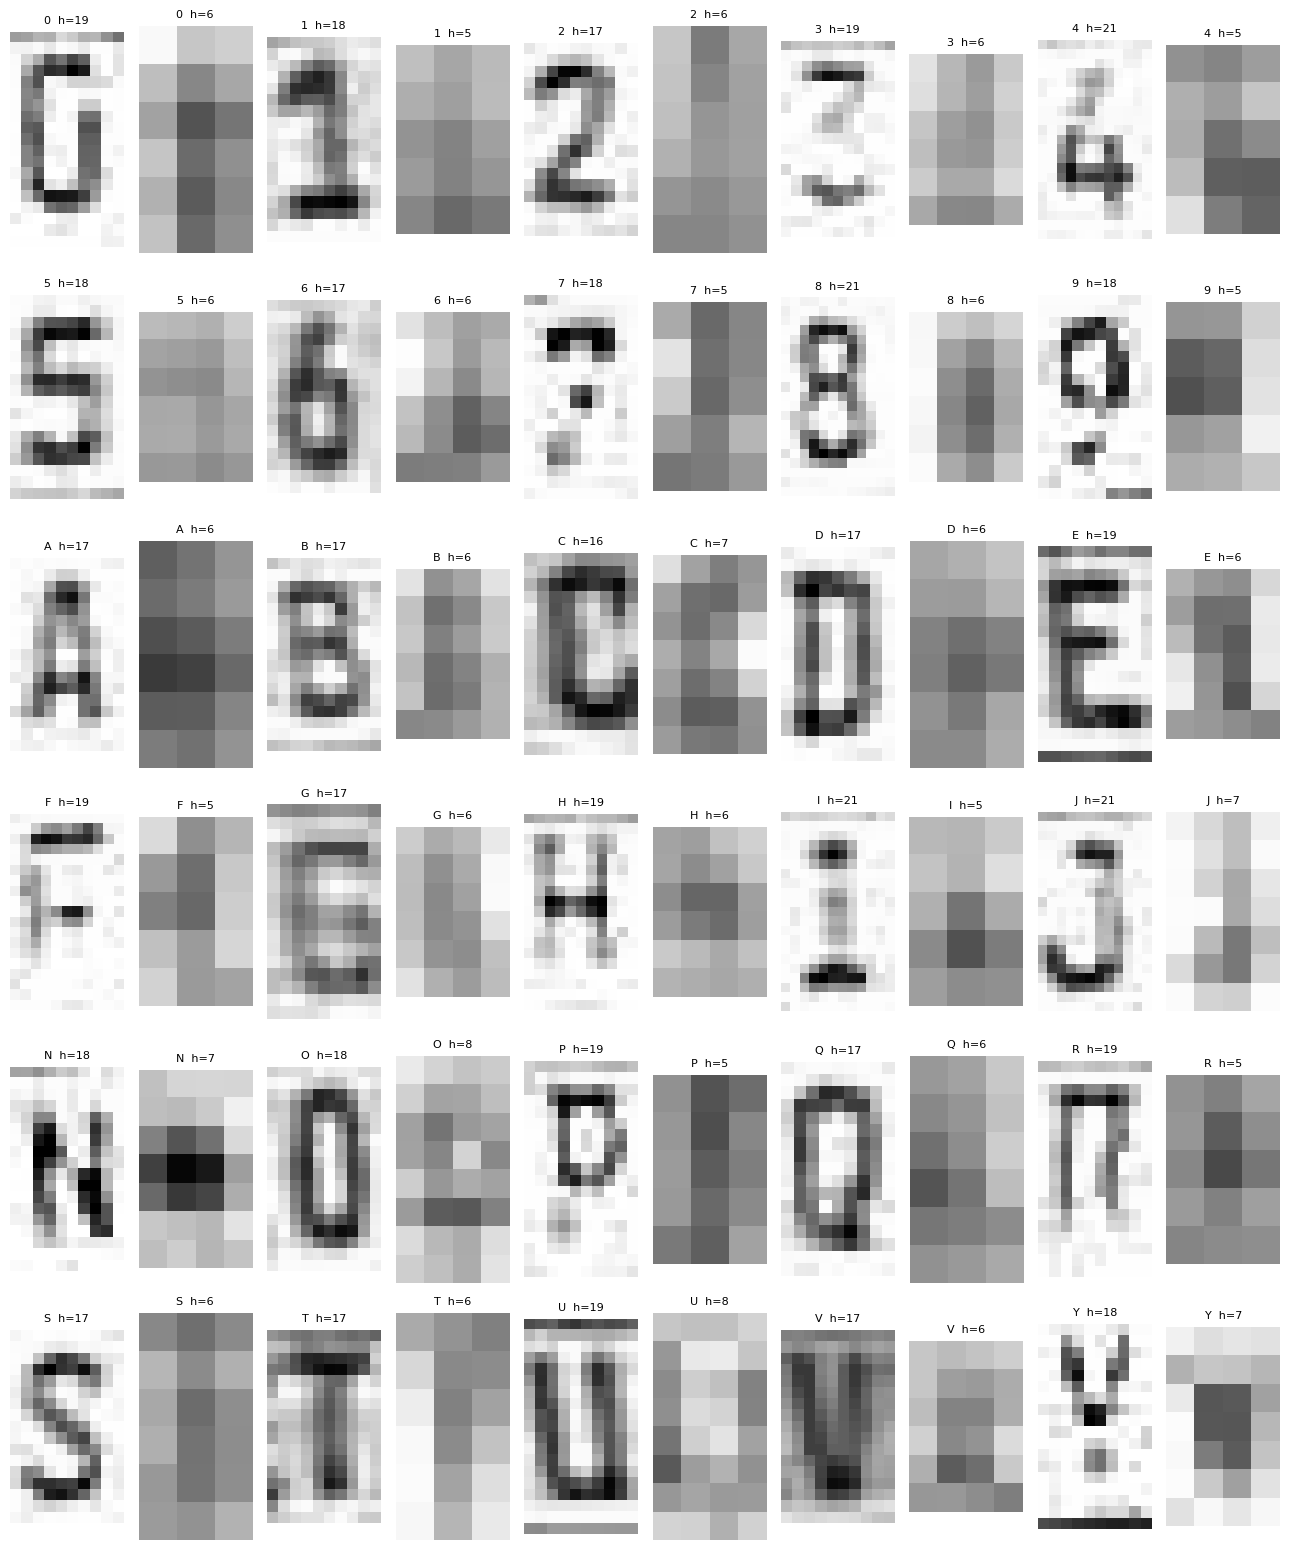


Spearman(frame_index, orig_h) over 27 groups:
count    27.000
mean      0.440
std       0.768
min      -0.942
25%      -0.244
50%       0.903
75%       0.958
max       0.980
Groups that are NOT clearly decreasing (corr > -0.5): 21
AVI3792.avi_SDQ2A25    0.980
AVI3792.avi_PRN6G80    0.978
AVI3789.avi_QUV5D92    0.975
AVI3788.avi_PUX0E55    0.973
AVI3789.avi_PRH0F33    0.972
AVI3789.avi_RBN3E71    0.969
AVI3789.avi_PRT8G20    0.961
AVI3791.avi_HPZ5D13    0.954
AVI3792.avi_TGG6E58    0.953
AVI3792.avi_SCN7E11    0.945


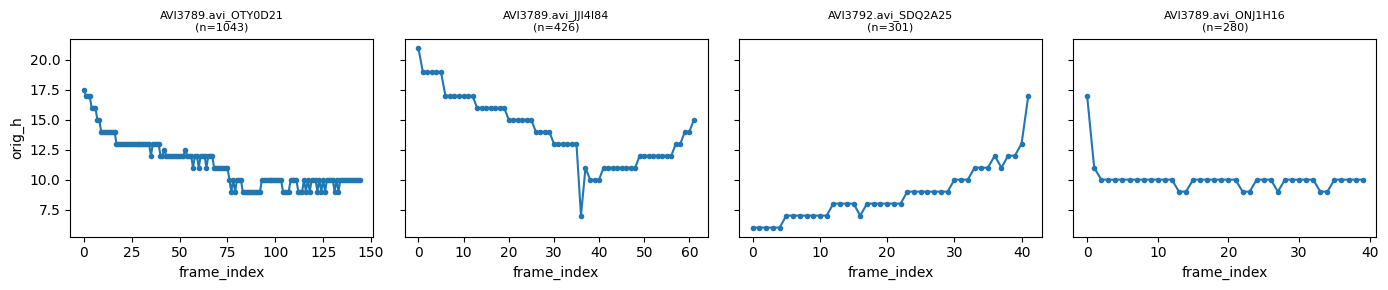

In [7]:
from PIL import Image

# Column of `df` holding the full path of each image (built in Cell 4).
# Change this name if Cell 4 used a different one.
PATH_COL = "img_path"
REQUIRED = [PATH_COL, "label", "orig_h", "orig_w", "group_id", "frame_index"]
missing = [c for c in REQUIRED if c not in df.columns]
assert not missing, f"df is missing columns: {missing}"

# ---------------------------------------------------------------
# 1) Real PNG size vs the size recorded in the manifest
# ---------------------------------------------------------------
# Why this matters: orig_h is our proxy for degradation (plate height in pixels in
# the original frame). If the PNGs were resized after cropping, the PNG size no
# longer tells us the original resolution, and orig_h in the manifest is the ONLY
# record of it. If they were not resized, both must match exactly.
def read_png_info(path):
    # Image.open only reads the file header, it does not decode the pixels,
    # so this is fast even for thousands of files.
    with Image.open(path) as im:
        w, h = im.size
        return w, h, im.mode


info = [read_png_info(p) for p in df[PATH_COL]]
df[["png_w", "png_h", "png_mode"]] = pd.DataFrame(info, index=df.index)

# Mode "L" = grayscale, "RGB"/"RGBA" = color. Color is irrelevant here, but the gray
# level is not, so we will convert with cv2.IMREAD_GRAYSCALE when loading.
print("PNG modes:")
print(df["png_mode"].value_counts().to_string())

resized = (df["png_w"] != df["orig_w"]) | (df["png_h"] != df["orig_h"])
print(f"\nPNGs whose size differs from the manifest: {resized.sum()} of {len(df)} ({resized.mean():.1%})")
print("Most common PNG sizes (w, h):")
print(df.groupby(["png_w", "png_h"]).size().sort_values(ascending=False).head(5).to_string())
if resized.any():
    print("\nExamples of mismatches:")
    print(df.loc[resized, ["orig_w", "orig_h", "png_w", "png_h"]].head().to_string())

# ---------------------------------------------------------------
# 2) Aspect ratio: crops should be 9:16 (width:height = 0.5625)
# ---------------------------------------------------------------
# The protocol cuts edge to edge of the plate, so every crop should have the same
# proportion. Outliers usually mean a bad annotation.
ratio = df["orig_w"] / df["orig_h"]
off_ratio = ((ratio - 9 / 16).abs() / (9 / 16) > 0.05).sum()
print(f"\nAspect ratio w/h (expected 0.5625):")
print(ratio.describe().round(4).to_string())
print(f"Crops more than 5% away from 9:16: {off_ratio}")

# ---------------------------------------------------------------
# 3) Distribution of orig_h (our degradation proxy)
# ---------------------------------------------------------------
quantiles = df["orig_h"].quantile([0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0])
print("\norig_h quantiles:")
print(quantiles.to_string())

# Candidate edges for 4 degradation bands (used later in Cell 15).
band_edges = df["orig_h"].quantile([0.25, 0.5, 0.75]).tolist()
print(f"Candidate 4-band edges (quartiles of orig_h): {band_edges}")

# The network input height is INPUT_H. A crop smaller than that is UPSCALED
# (interpolation invents pixels, so the choice of method matters), a larger one is
# DOWNSCALED (INTER_AREA is the usual choice). This decides the method in Cell 9.
up_share = (df["orig_h"] < INPUT_H).mean()
print(f"Crops upscaled to INPUT_H={INPUT_H}: {up_share:.1%} | downscaled: {1 - up_share:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(df["orig_h"], bins=40)
axes[0].axvline(INPUT_H, color="red", linestyle="--", label=f"INPUT_H = {INPUT_H}")
axes[0].set_title("orig_h (crop height in pixels)")
axes[0].set_xlabel("pixels")
axes[0].legend()
axes[1].hist(ratio, bins=40)
axes[1].axvline(9 / 16, color="red", linestyle="--", label="9:16")
axes[1].set_title("orig_w / orig_h")
axes[1].legend()
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------
# 4) Example grid: least vs most degraded crop of each class
# ---------------------------------------------------------------
# IMPORTANT: imshow stretches contrast per image by default, which would hide the
# real gray level (and the gray level is information here). Fixing vmin/vmax to
# the full 0-255 range shows each image exactly as the network will see it.
labels = sorted(df["label"].unique())
CLASSES_PER_ROW = 5
n_rows = int(np.ceil(len(labels) / CLASSES_PER_ROW))
fig, axes = plt.subplots(
    n_rows, CLASSES_PER_ROW * 2,
    figsize=(CLASSES_PER_ROW * 2 * 1.3, n_rows * 2.6),
    squeeze=False,
)
for ax in axes.ravel():
    ax.axis("off")

for i, lab in enumerate(labels):
    r, c = divmod(i, CLASSES_PER_ROW)
    sub = df[df["label"] == lab].sort_values("orig_h")
    # Largest orig_h first (least degraded), then smallest (most degraded).
    for j, row in enumerate([sub.iloc[-1], sub.iloc[0]]):
        ax = axes[r, c * 2 + j]
        img = cv2.imread(str(row[PATH_COL]), cv2.IMREAD_GRAYSCALE)
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{lab}  h={row['orig_h']}", fontsize=8)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------
# 5) Sanity check: orig_h should shrink as the vehicle moves away
# ---------------------------------------------------------------
# Within each group (one plate in one video) the plate gets smaller over the frames,
# so orig_h vs frame_index should be roughly monotonic decreasing. Spearman rank
# correlation measures monotonicity: close to -1 means "decreasing", 0 means no trend.
# We take the median orig_h per frame, because the 7 characters of a plate share a frame.
def frame_corr(d):
    s = d.groupby("frame_index")["orig_h"].median()
    if len(s) < 5 or s.nunique() < 2:
        return np.nan
    return s.index.to_series().corr(s, method="spearman")


corrs = pd.Series({gid: frame_corr(d) for gid, d in df.groupby("group_id")}).dropna()
print(f"\nSpearman(frame_index, orig_h) over {len(corrs)} groups:")
print(corrs.describe().round(3).to_string())

suspicious = corrs[corrs > -0.5].sort_values(ascending=False)
print(f"Groups that are NOT clearly decreasing (corr > -0.5): {len(suspicious)}")
if len(suspicious):
    print(suspicious.head(10).round(3).to_string())

# Visual check on the 4 largest groups.
top_groups = df["group_id"].value_counts().head(4).index
fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for ax, gid in zip(axes, top_groups):
    s = df[df["group_id"] == gid].groupby("frame_index")["orig_h"].median()
    ax.plot(s.index, s.values, marker=".", linestyle="-")
    ax.set_title(f"{gid}\n(n={int((df['group_id'] == gid).sum())})", fontsize=8)
    ax.set_xlabel("frame_index")
axes[0].set_ylabel("orig_h")
plt.tight_layout()
plt.show()

## 6 - Label encoding

In [8]:
# ---------------------------------------------------------------
# 1) Label -> class index
# ---------------------------------------------------------------
# The classifier outputs one score (logit) per class, so the labels must become
# integers. We keep the FIXED 36-index scheme from Cell 2 (A-Z = 0-25, 0-9 = 26-35)
# instead of numbering only the classes we have. Reason: the output layer always has
# 36 neurons, so when Z, K, X, W, L or M get enough data later, they plug into the
# same network shape and the same indices, and old checkpoints stay compatible.
IDX_TO_CLASS = {i: c for c, i in CLASS_TO_IDX.items()}

df["y"] = df["label"].map(CLASS_TO_IDX)
assert df["y"].notna().all(), "Some labels have no class index"
df["y"] = df["y"].astype(int)

# ---------------------------------------------------------------
# 2) Active classes
# ---------------------------------------------------------------
# A class is "active" if it has samples after the filtering in Cell 4. The excluded
# classes are already gone from df, and classes with no data at all (here, "M")
# never appeared, so both are inactive automatically.
present = set(df["label"].unique())
ACTIVE_CLASSES = [c for c in ALL_CLASSES if c in present]
ACTIVE_IDX = [CLASS_TO_IDX[c] for c in ACTIVE_CLASSES]
INACTIVE_CLASSES = [c for c in ALL_CLASSES if c not in present]

# Boolean mask over the 36 outputs: True = this class can be predicted.
# Cell 10 will set the logits of the False entries to -inf before the softmax, so
# the network can never predict a class it was not trained on, and those classes
# take no probability mass. They also receive no gradient: their output neurons
# stay at their random initial weights, so they will need training once real data
# for them exists.
# Note: this is NOT a letter/digit mask. It only removes classes that do not exist
# in this version of the dataset.
ACTIVE_MASK = torch.zeros(NUM_CLASSES, dtype=torch.bool)
ACTIVE_MASK[ACTIVE_IDX] = True
ACTIVE_MASK = ACTIVE_MASK.to(DEVICE)

# ---------------------------------------------------------------
# 3) Sanity checks
# ---------------------------------------------------------------
assert set(df["y"].unique()) <= set(ACTIVE_IDX)
assert int(ACTIVE_MASK.sum()) == len(ACTIVE_CLASSES)
assert all(IDX_TO_CLASS[CLASS_TO_IDX[c]] == c for c in ALL_CLASSES)  # round trip

# is_letter (from Cell 4) is kept in df for a future version, but it is NOT used by
# the model. Because letters are indices 0-25 and digits 26-35, the type is also
# recoverable from the index: this checks that the two agree.
assert (df["is_letter"] == (df["y"] < 26)).all(), "is_letter disagrees with the class index"

n_letters = sum(c.isalpha() for c in ACTIVE_CLASSES)
n_digits = len(ACTIVE_CLASSES) - n_letters
print(f"Active classes: {len(ACTIVE_CLASSES)} ({n_letters} letters + {n_digits} digits) out of {NUM_CLASSES} outputs")

excluded_in_inactive = [c for c in INACTIVE_CLASSES if c in EXCLUDED_LABELS]
no_data = [c for c in INACTIVE_CLASSES if c not in EXCLUDED_LABELS]
print(f"Inactive because excluded: {excluded_in_inactive}")
print(f"Inactive because there is no data: {no_data}")

print("\nIndex -> class for the active classes:")
print("  ".join(f"{i}:{IDX_TO_CLASS[i]}" for i in ACTIVE_IDX))

df[["label", "y", "is_letter"]].head()

Active classes: 30 (20 letters + 10 digits) out of 36 outputs
Inactive because excluded: ['K', 'L', 'W', 'X', 'Z']
Inactive because there is no data: ['M']

Index -> class for the active classes:
0:A  1:B  2:C  3:D  4:E  5:F  6:G  7:H  8:I  9:J  13:N  14:O  15:P  16:Q  17:R  18:S  19:T  20:U  21:V  24:Y  26:0  27:1  28:2  29:3  30:4  31:5  32:6  33:7  34:8  35:9


,label,y,is_letter
0,R,17,True
1,E,4,True
2,D,3,True
3,1,27,False
4,C,2,True


## 7 - Random stratified split

In [9]:
# Row positions must equal the index labels, because we split by index below (Cell 4 did reset_index).
assert df.index.equals(pd.RangeIndex(len(df))), "df index is not 0..N-1, run reset_index first"

# ---------------------------------------------------------------
# 1) Two-step split: first carve out the test set, then split the rest into train/val
# ---------------------------------------------------------------
idx_all = df.index.to_numpy()  # every row position, as a numpy array

# Step 1: separate the test set (15% of everything).
idx_trainval, idx_test = train_test_split(
    idx_all,                       # what to split: row positions, not the images themselves
    test_size=TEST_FRAC,           # fraction that goes to the test set
    stratify=df["label"],          # keep the same class proportions in both parts
    random_state=SEED,             # makes the shuffle reproducible
)

# Val must be 15% of the ORIGINAL data, but step 2 only sees the remaining 85%,
# so the fraction has to be rescaled: 0.15 / (0.70 + 0.15) = about 0.176.
val_rel = VAL_FRAC / (TRAIN_FRAC + VAL_FRAC)

# Step 2: split the remaining rows into train and validation.
idx_train, idx_val = train_test_split(
    idx_trainval,                              # rows left after removing the test set
    test_size=val_rel,                         # rescaled validation fraction
    stratify=df.loc[idx_trainval, "label"],    # stratify using only the labels of these rows
    random_state=SEED,                         # same seed, same result on every run
)

# ---------------------------------------------------------------
# 2) Record the split in the DataFrame
# ---------------------------------------------------------------
df["split"] = ""                       # start with an empty marker for every row
df.loc[idx_train, "split"] = "train"   # mark the training rows
df.loc[idx_val, "split"] = "val"       # mark the validation rows
df.loc[idx_test, "split"] = "test"     # mark the test rows

assert (df["split"] != "").all()                                    # every row got a split
assert len(idx_train) + len(idx_val) + len(idx_test) == len(df)     # nothing lost or duplicated
assert len(set(idx_train) & set(idx_val) & set(idx_test)) == 0      # no row in all three sets

# Save the split so any later run (or the future group-based split) can reuse or compare it.
# crop_id is the key (stable and unique); group_id is kept to study leakage afterwards.
split_path = OUTPUT_DIR / "split_random.csv"                        # where the split file goes
df[["crop_id", "group_id", "label", "split"]].to_csv(split_path, index=False)  # write it without the index
print(f"Split saved to {split_path}")                               # confirm the location

# ---------------------------------------------------------------
# 3) Sizes and per-class counts
# ---------------------------------------------------------------
print("\nRows per split:")                                           # section title
print(df["split"].value_counts()[["train", "val", "test"]].to_string())  # sizes in a fixed order

counts = pd.crosstab(df["label"], df["split"])[["train", "val", "test"]]  # classes x splits table
print("\nSamples per class in each split:")                         # section title
print(counts.T.to_string())                                       # transposed: splits as rows, classes as columns
print(f"Smallest class count -> train: {counts['train'].min()} | val: {counts['val'].min()} | test: {counts['test'].min()}")  # weakest classes per split

# ---------------------------------------------------------------
# 4) Quantify the leakage
# ---------------------------------------------------------------
# Leakage = near-identical frames of the same plate landing in train AND test.
groups = {s: set(df.loc[df["split"] == s, "group_id"]) for s in ["train", "val", "test"]}  # group ids per split
in_all_three = groups["train"] & groups["val"] & groups["test"]    # groups present in all three splits

print(f"\nTotal groups: {df['group_id'].nunique()}")               # how many plates/sequences exist
print(f"Groups per split -> train: {len(groups['train'])} | val: {len(groups['val'])} | test: {len(groups['test'])}")  # group count per split
print(f"Groups present in all three splits: {len(in_all_three)}")  # direct measure of the overlap

for s in ["val", "test"]:                                          # check both held-out splits
    rows = df[df["split"] == s]                                    # rows of this split
    shared = rows["group_id"].isin(groups["train"]).mean()         # share of rows whose group also exists in train
    print(f"{s}: {shared:.1%} of the rows belong to a group that also appears in train")  # the leakage figure

top = df["group_id"].value_counts(normalize=True).head(3)          # biggest groups as a share of all rows
print("\nShare of the dataset held by the 3 biggest groups:")      # section title
print((top * 100).round(1).astype(str).add("%").to_string())       # pretty percentages

Split saved to /content/outputs/split_random.csv

Rows per split:
split
train    3799
val       815
test      815

Samples per class in each split:
label    0    1    2   3    4    5   6    7    8   9   A    B   C    D    E   F    G   H    I    J    N    O    P   Q    R    S    T   U   V    Y
split                                                                                                                                            
train  206  373  264  91  194  152  91  106  101  96  70  129  67  192  100  86  120  72  132  113  102  133  161  49  133  100  152  43  52  119
val     44   80   57  20   41   32  20   23   22  20  15   28  14   41   22  19   26  15   28   24   22   29   34  11   29   22   32   9  11   25
test    44   80   57  20   41   33  20   23   22  21  15   28  14   41   22  18   26  15   28   24   22   29   35  10   28   21   33   9  11   25
Smallest class count -> train: 43 | val: 9 | test: 9

Total groups: 27
Groups per split -> train: 27 | val: 27 | test: 27


## 8 - Image loading and normalization

Loaded 5429 images in 0.3s | shape (5429, 64, 36) | dtype uint8

Train statistics (0-1 scale): mean = 0.6971 | std = 0.2215
val: mean = 0.6907 | std = 0.2237
test: mean = 0.6925 | std = 0.2239
After normalization (train): mean = 0.0000 | std = 1.0000
Value range after normalization: -3.15 to 1.37


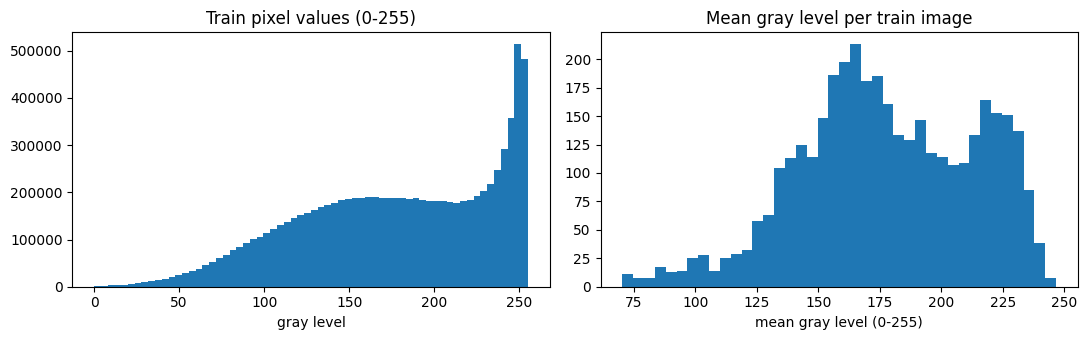


Saved /content/outputs/normalization.json


In [10]:
# ---------------------------------------------------------------
# 1) Loading helper: grayscale + fixed-size resize
# ---------------------------------------------------------------
def load_gray_resized(path):
    """Read one image as 8-bit grayscale and resize it to the network input size."""
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)  # color is dropped, gray levels kept exactly as stored (0-255)
    if img is None:  # cv2.imread does not raise on failure, it returns None
        raise IOError(f"Could not read image: {path}")  # fail loudly with the offending path
    # Shrinking: INTER_AREA averages source pixels (no aliasing). Enlarging: INTER_LINEAR.
    # This is the usual OpenCV recommendation and it is deterministic, so train and inference match.
    interp = cv2.INTER_AREA if img.shape[0] > INPUT_H else cv2.INTER_LINEAR  # choose by direction of the resize
    return cv2.resize(img, (INPUT_W, INPUT_H), interpolation=interp)  # dsize is (width, height), not (h, w)


# ---------------------------------------------------------------
# 2) Load every image once and keep it in RAM
# ---------------------------------------------------------------
t0 = time.time()  # start a timer
# Stack all images into one array of shape (N, H, W), in the same row order as df.
# Because the order matches df, IMAGES[i] is the image of df.iloc[i], so the split indices
# from Cell 7 (idx_train, idx_val, idx_test) can index IMAGES directly.
IMAGES = np.stack([load_gray_resized(p) for p in df["img_path"]])  # uint8 keeps the cache small (about 13 MB)
print(f"Loaded {len(IMAGES)} images in {time.time() - t0:.1f}s | shape {IMAGES.shape} | dtype {IMAGES.dtype}")  # sanity print
assert IMAGES.shape == (len(df), INPUT_H, INPUT_W)  # one image per row, all the same size

# ---------------------------------------------------------------
# 3) Global mean/std from the TRAINING set only
# ---------------------------------------------------------------
# Why only train? Validation and test must behave like data the model has never seen.
# Computing statistics on them would let information about them leak into the pipeline.
# Why global (one mean and one std for the whole dataset) and not per image?
# Per-image normalization or histogram equalization would erase brightness differences
# between images, and here the gray level IS information (bright vs dark plates, etc.).
train_pixels = IMAGES[idx_train].astype(np.float64) / 255.0  # train images only, scaled from 0-255 to 0-1
MEAN = float(train_pixels.mean())  # average gray level over every training pixel
STD = float(train_pixels.std())  # spread of the gray levels over every training pixel
assert STD > 0, "Standard deviation is zero: images are constant?"  # would break the division below
print(f"\nTrain statistics (0-1 scale): mean = {MEAN:.4f} | std = {STD:.4f}")  # the two numbers we keep

# For comparison only (NOT used for anything): the held-out sets should look similar.
for name, idx in [("val", idx_val), ("test", idx_test)]:  # loop over the held-out splits
    pix = IMAGES[idx].astype(np.float64) / 255.0  # same scaling as above
    print(f"{name}: mean = {pix.mean():.4f} | std = {pix.std():.4f}")  # a large gap would signal a distribution shift

# ---------------------------------------------------------------
# 4) The normalization function used from now on
# ---------------------------------------------------------------
def normalize(x_uint8):
    """uint8 array (0-255) -> float32 with roughly zero mean and unit variance."""
    x = x_uint8.astype(np.float32) / 255.0  # scale to 0-1
    return (x - MEAN) / STD  # center and scale with the TRAIN statistics

check = normalize(IMAGES[idx_train])  # apply it to the training set as a check
print(f"After normalization (train): mean = {check.mean():.4f} | std = {check.std():.4f}")  # should be about 0 and 1
print(f"Value range after normalization: {check.min():.2f} to {check.max():.2f}")  # useful to know the input range

# ---------------------------------------------------------------
# 5) Look at the gray levels
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))  # two side-by-side plots
axes[0].hist(IMAGES[idx_train].ravel(), bins=64)  # distribution of every training pixel value
axes[0].set_title("Train pixel values (0-255)")  # what the left plot shows
axes[0].set_xlabel("gray level")  # x axis label
axes[1].hist(IMAGES[idx_train].reshape(len(idx_train), -1).mean(axis=1), bins=40)  # one mean per image
axes[1].set_title("Mean gray level per train image")  # what the right plot shows
axes[1].set_xlabel("mean gray level (0-255)")  # x axis label
plt.tight_layout()  # avoid overlapping labels
plt.show()  # draw the figure

# ---------------------------------------------------------------
# 6) Save the values: inference MUST use exactly the same ones
# ---------------------------------------------------------------
norm_info = {  # everything needed to reproduce the preprocessing later
    "mean": MEAN,  # train mean on the 0-1 scale
    "std": STD,  # train std on the 0-1 scale
    "input_w": INPUT_W,  # network input width
    "input_h": INPUT_H,  # network input height
    "n_train_images": int(len(idx_train)),  # how many images the statistics came from
    "resize": "INTER_AREA when shrinking, INTER_LINEAR when enlarging",  # resize rule used
}
with open(OUTPUT_DIR / "normalization.json", "w") as f:  # open the output file
    json.dump(norm_info, f, indent=2)  # write the values as readable JSON
print(f"\nSaved {OUTPUT_DIR / 'normalization.json'}")  # confirm the location

## 9 - Dataset and DataLoaders

Samples -> train: 3799 | val: 815 | test: 815
Batches per epoch -> train: 59 | val: 7 | test: 7

Batch images: shape (64, 1, 64, 36) | dtype torch.float32
Batch values: min -3.15 | max 1.37 | mean -0.01 | std 0.98
Batch labels: shape (64,) | dtype torch.int64 | min 0 | max 33


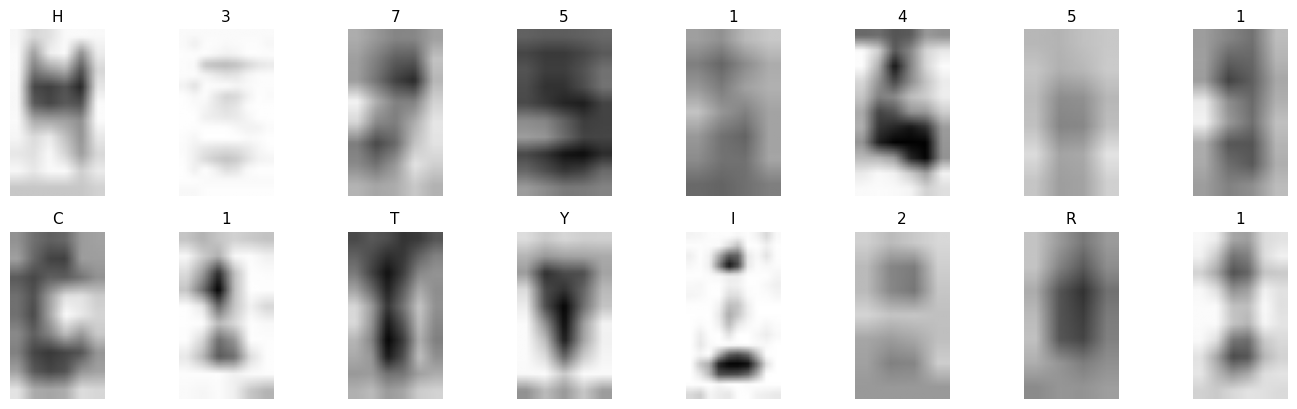

In [11]:
# ---------------------------------------------------------------
# 1) Dataset: what the model sees for one sample
# ---------------------------------------------------------------
class PlateCharDataset(Dataset):  # a PyTorch Dataset must implement __len__ and __getitem__
    """Holds normalized grayscale crops (1 x H x W) and their class indices."""

    def __init__(self, images_u8, y):  # images_u8: (N, H, W) uint8 from Cell 8, y: (N,) class indices
        # Normalize ONCE here instead of at every access: the data is small, so it is cheaper
        # to keep the ready-to-use float tensors in RAM (about 50 MB for the whole dataset).
        x = normalize(images_u8)  # Cell 8 function: /255, then (x - MEAN) / STD, float32 numpy
        self.x = torch.from_numpy(x).unsqueeze(1)  # add the channel dimension: (N, H, W) -> (N, 1, H, W)
        self.y = torch.from_numpy(np.asarray(y, dtype=np.int64))  # CrossEntropyLoss expects int64 targets

    def __len__(self):  # how many samples there are
        return len(self.y)  # DataLoader uses this to know the epoch size

    def __getitem__(self, i):  # return the i-th sample
        # NO augmentation in this version. When it is added later, this is the place: it runs
        # at every access, so each epoch would see a slightly different version of the image.
        # Remember the vertical position of the pixels is signal: only tiny shifts are safe.
        return self.x[i], self.y[i]  # (1, H, W) float32 image and its class index


# Build one Dataset per split. IMAGES and df share the same row order, and idx_* hold row positions.
train_ds = PlateCharDataset(IMAGES[idx_train], df.loc[idx_train, "y"].to_numpy())  # training samples
val_ds = PlateCharDataset(IMAGES[idx_val], df.loc[idx_val, "y"].to_numpy())  # validation samples
test_ds = PlateCharDataset(IMAGES[idx_test], df.loc[idx_test, "y"].to_numpy())  # test samples
print(f"Samples -> train: {len(train_ds)} | val: {len(val_ds)} | test: {len(test_ds)}")  # sizes per split

# ---------------------------------------------------------------
# 2) DataLoaders: batching and shuffling
# ---------------------------------------------------------------
g = torch.Generator().manual_seed(SEED)  # dedicated random generator so the shuffle order is reproducible

train_loader = DataLoader(
    train_ds,  # the dataset to draw from
    batch_size=BATCH_SIZE,  # samples per training step
    shuffle=True,  # new random order every epoch, so the model does not learn the order
    drop_last=True,  # drop the incomplete last batch: tiny batches make BatchNorm statistics noisy
    generator=g,  # use the seeded generator for the shuffling
    num_workers=NUM_WORKERS,  # 0 = load in the main process (data is already in RAM)
    pin_memory=DEVICE.type == "cuda",  # speeds up CPU -> GPU copies
)
val_loader = DataLoader(
    val_ds,  # validation dataset
    batch_size=BATCH_SIZE * 2,  # no gradients are stored in evaluation, so bigger batches fit
    shuffle=False,  # fixed order: predictions line up with idx_val row by row
    num_workers=NUM_WORKERS,  # same loading mode as above
    pin_memory=DEVICE.type == "cuda",  # same transfer speed-up
)
test_loader = DataLoader(
    test_ds,  # test dataset
    batch_size=BATCH_SIZE * 2,  # larger batches for evaluation
    shuffle=False,  # fixed order: predictions line up with idx_test row by row
    num_workers=NUM_WORKERS,  # same loading mode as above
    pin_memory=DEVICE.type == "cuda",  # same transfer speed-up
)
print(f"Batches per epoch -> train: {len(train_loader)} | val: {len(val_loader)} | test: {len(test_loader)}")  # loop lengths

# ---------------------------------------------------------------
# 3) Sanity check on one batch
# ---------------------------------------------------------------
xb, yb = next(iter(train_loader))  # pull a single batch of training data
print(f"\nBatch images: shape {tuple(xb.shape)} | dtype {xb.dtype}")  # expect (BATCH_SIZE, 1, INPUT_H, INPUT_W) float32
print(f"Batch values: min {xb.min():.2f} | max {xb.max():.2f} | mean {xb.mean():.2f} | std {xb.std():.2f}")  # mean/std near 0/1
print(f"Batch labels: shape {tuple(yb.shape)} | dtype {yb.dtype} | min {yb.min()} | max {yb.max()}")  # expect int64 in 0..35
assert xb.shape == (BATCH_SIZE, 1, INPUT_H, INPUT_W)  # exact shape the network expects
assert set(yb.tolist()) <= set(ACTIVE_IDX)  # every label belongs to an active class (Cell 6)
g.manual_seed(SEED)  # reset the generator: the check above consumed one shuffle, this keeps training reproducible

# Look at the batch: the most important check is that each image matches its label.
n_show = 16  # how many images to display
fig, axes = plt.subplots(2, 8, figsize=(14, 4.2))  # a 2 x 8 grid
for ax, img, lab in zip(axes.ravel(), xb[:n_show], yb[:n_show]):  # one axis per image
    shown = (img[0].numpy() * STD + MEAN) * 255  # undo the normalization to see the original gray levels
    ax.imshow(shown, cmap="gray", vmin=0, vmax=255)  # fixed range keeps the true brightness
    ax.set_title(IDX_TO_CLASS[int(lab)], fontsize=11)  # decoded class letter/digit above the image
    ax.axis("off")  # hide the axes
plt.tight_layout()  # avoid overlapping titles
plt.show()  # draw the figure

## 10 - Model

In [12]:
# ---------------------------------------------------------------
# 1) Model builder: ResNet18 for 1-channel input and 36 outputs
# ---------------------------------------------------------------
def build_model(pretrained=USE_PRETRAINED):  # a function so later rounds / checkpoint loading can rebuild it
    weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None  # ImageNet weights or random init
    net = models.resnet18(weights=weights)  # downloads the weights the first time (Colab has internet)

    old_conv = net.conv1  # original first layer: expects 3 channels (RGB)
    new_conv = nn.Conv2d(  # replacement that expects 1 channel (gray)
        1,  # input channels: a single gray channel
        old_conv.out_channels,  # keep the same number of filters (64)
        kernel_size=old_conv.kernel_size,  # keep the 7x7 kernel
        stride=old_conv.stride,  # keep stride 2
        padding=old_conv.padding,  # keep padding 3
        bias=False,  # the original has no bias (BatchNorm follows)
    )
    # Sum the 3 RGB filters into one. For a gray image (R = G = B = x), the original layer
    # computes (w_r + w_g + w_b) * x, which is exactly what one summed filter computes. So the
    # pretrained knowledge in the first layer is preserved instead of thrown away.
    with torch.no_grad():  # we are only copying numbers, no gradient tracking needed
        new_conv.weight.copy_(old_conv.weight.sum(dim=1, keepdim=True))  # (64,3,7,7) -> (64,1,7,7)
    net.conv1 = new_conv  # plug the new layer in

    net.fc = nn.Linear(net.fc.in_features, NUM_CLASSES)  # new classifier head: 512 features -> 36 logits
    return net, old_conv.weight.detach().clone()  # also return the original weights for the check below


model, old_conv_weight = build_model()  # create the network
model = model.to(DEVICE)  # move all parameters to the GPU (or stay on CPU)

# ---------------------------------------------------------------
# 2) Masking the inactive classes
# ---------------------------------------------------------------
def mask_inactive(logits):
    """Set the logits of inactive classes to -inf so softmax gives them probability 0."""
    return logits.masked_fill(~ACTIVE_MASK, float("-inf"))  # ~ inverts the mask; it broadcasts over the batch

# Use this function in training (Cell 11/12) AND in evaluation (Cell 14), so the model can never
# predict Z, K, X, W, L or M. This is not a letter/digit mask, only a "class exists" mask.

# ---------------------------------------------------------------
# 3) Sanity checks
# ---------------------------------------------------------------
n_params = sum(p.numel() for p in model.parameters())  # total number of weights
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)  # weights that will be updated
print(f"Parameters: {n_params:,} total | {n_train:,} trainable")  # about 11.2 million

# Check A: the adapted first layer reproduces the original one on gray images.
x_gray = torch.randn(2, 1, INPUT_H, INPUT_W, device=DEVICE)  # random fake gray images
out_new = F.conv2d(x_gray, model.conv1.weight, stride=2, padding=3)  # adapted layer on 1 channel
out_old = F.conv2d(x_gray.repeat(1, 3, 1, 1), old_conv_weight.to(DEVICE), stride=2, padding=3)  # original on R=G=B
assert torch.allclose(out_new, out_old, atol=1e-4), "conv1 adaptation is not equivalent"  # must match
print("OK: summed conv1 matches the original conv1 on gray input")  # confirmation

# Check B: shape trace. A 36x64 image shrinks fast through ResNet18, worth seeing once.
model.eval()  # eval mode: BatchNorm uses running statistics and is not updated by this check
with torch.no_grad():  # no gradients needed for a shape check
    t = torch.zeros(1, 1, INPUT_H, INPUT_W, device=DEVICE)  # one fake image
    print(f"\nInput: {tuple(t.shape)}")  # (1, 1, H, W)
    for name in ["conv1", "bn1", "relu", "maxpool", "layer1", "layer2", "layer3", "layer4"]:  # stages in order
        t = getattr(model, name)(t)  # run this stage
        if name in ["conv1", "maxpool", "layer1", "layer2", "layer3", "layer4"]:  # print only the size-changing ones
            print(f"after {name:8s}: {tuple(t.shape)}")  # (1, channels, h, w)

    # Check C: the mask. Probabilities of inactive classes must be 0 and the rest must sum to 1.
    x_fake = torch.randn(8, 1, INPUT_H, INPUT_W, device=DEVICE)  # random batch
    logits = mask_inactive(model(x_fake))  # forward pass, then mask
    probs = logits.softmax(dim=1)  # convert logits to probabilities
    inactive = ~ACTIVE_MASK  # positions of the inactive classes
    assert probs[:, inactive].abs().max() == 0, "inactive classes got probability"  # exactly zero
    assert torch.allclose(probs.sum(dim=1), torch.ones(8, device=DEVICE), atol=1e-5)  # still a distribution
    assert ACTIVE_MASK[probs.argmax(dim=1)].all(), "predicted an inactive class"  # argmax is always active
    print(f"\nOK: {int(inactive.sum())} inactive classes have probability 0 and the rest sum to 1")  # confirmation

model.train()  # back to training mode, which is what the training loop expects

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 99.3MB/s]


Parameters: 11,188,708 total | 11,188,708 trainable
OK: summed conv1 matches the original conv1 on gray input

Input: (1, 1, 64, 36)
after conv1   : (1, 64, 32, 18)
after maxpool : (1, 64, 16, 9)
after layer1  : (1, 64, 16, 9)
after layer2  : (1, 128, 8, 5)
after layer3  : (1, 256, 4, 3)
after layer4  : (1, 512, 2, 2)

OK: 6 inactive classes have probability 0 and the rest sum to 1


ResNet(
  (conv1): Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

 ## 11 - Loss, optimizer and class imbalance

In [13]:
# ---------------------------------------------------------------
# 1) Class weights from the TRAINING frequencies
# ---------------------------------------------------------------
# 1.0 = inverse frequency (rare classes count a lot more); 0.5 = inverse square root (gentler).
CLASS_WEIGHT_POWER = 1.0  # how aggressively rare classes are boosted

y_train = df.loc[idx_train, "y"].to_numpy()  # class index of every training sample
train_counts = np.bincount(y_train, minlength=NUM_CLASSES)  # samples per class, over all 36 positions
active = np.array(ACTIVE_IDX)  # positions of the 30 active classes
assert train_counts[active].min() > 0, "an active class has no training samples"  # needed to divide below

weights_np = np.zeros(NUM_CLASSES, dtype=np.float64)  # inactive classes keep weight 0 (never a target)
weights_np[active] = (1.0 / train_counts[active]) ** CLASS_WEIGHT_POWER  # rarer class -> bigger weight
weights_np[active] /= weights_np[active].mean()  # rescale so the average weight is 1 (keeps the loss scale stable)
class_weights_tensor = torch.tensor(weights_np, dtype=torch.float32, device=DEVICE)  # the form the loss expects

# Show the weights whether or not they are used, to understand the imbalance (rarest classes first).
weights_table = pd.DataFrame({  # one row per active class
    "class": [IDX_TO_CLASS[i] for i in active],  # decoded letter/digit
    "train_count": train_counts[active],  # how many training samples it has
    "weight": weights_np[active].round(3),  # the weight it would get
}).sort_values("train_count")  # rarest first
print(f"Class weights (power = {CLASS_WEIGHT_POWER}), used in training: {USE_CLASS_WEIGHTS}")  # state of the switch
print(weights_table.to_string(index=False))  # full table

# ---------------------------------------------------------------
# 2) Loss, optimizer and scheduler in one function
# ---------------------------------------------------------------
# A function, so round 2 (with class weights) can rebuild everything cleanly for a fresh model.
def make_training_components(net, use_class_weights):
    weight = class_weights_tensor if use_class_weights else None  # None = every class counts the same
    criterion = nn.CrossEntropyLoss(weight=weight)  # softmax + negative log-likelihood, with optional class weights
    # AdamW = Adam with weight decay applied correctly (decoupled from the gradient update).
    optimizer = torch.optim.AdamW(
        net.parameters(),  # every weight of the network is updated
        lr=LEARNING_RATE,  # step size
        weight_decay=WEIGHT_DECAY,  # mild regularization that shrinks weights
    )
    if SCHEDULER == "cosine":  # smooth decay of the learning rate from lr to ~0
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)  # one step per EPOCH
    elif SCHEDULER == "onecycle":  # warm-up to a peak, then decay
        scheduler = torch.optim.lr_scheduler.OneCycleLR(
            optimizer,
            max_lr=LEARNING_RATE,  # peak learning rate
            epochs=EPOCHS,  # total epochs the cycle spans
            steps_per_epoch=len(train_loader),  # batches per epoch (from Cell 9)
        )  # one step per BATCH
    else:  # protect against a typo in the config
        raise ValueError(f"Unknown SCHEDULER: {SCHEDULER}")  # fail with a clear message
    return criterion, optimizer, scheduler  # the three pieces the training loop needs


# Tells Cell 12 when to call scheduler.step(): OneCycle every batch, Cosine every epoch.
SCHEDULER_STEPS_PER_BATCH = SCHEDULER == "onecycle"  # True or False

def masked_loss(criterion, logits, y):
    """Loss over the active classes only: inactive logits become -inf before the softmax."""
    return criterion(mask_inactive(logits), y)  # mask_inactive comes from Cell 10

criterion, optimizer, scheduler = make_training_components(model, USE_CLASS_WEIGHTS)  # for the model from Cell 10
print(f"\nOptimizer: AdamW | lr {LEARNING_RATE} | weight decay {WEIGHT_DECAY}")  # summary
print(f"Scheduler: {SCHEDULER} (stepped per {'batch' if SCHEDULER_STEPS_PER_BATCH else 'epoch'})")  # when it steps

# ---------------------------------------------------------------
# 3) Sanity checks with one real batch (no weight update)
# ---------------------------------------------------------------
model.eval()  # eval mode so this check does not change BatchNorm statistics
xb, yb = next(iter(train_loader))  # one training batch
xb, yb = xb.to(DEVICE), yb.to(DEVICE)  # move it to the same device as the model
loss = masked_loss(criterion, model(xb), yb)  # forward pass and loss (gradients are tracked)
loss.backward()  # backward pass: computes the gradients, does not change the weights

# At the start the network guesses at random, so the loss should be near ln(30) = 3.40.
print(f"\nInitial loss: {loss.item():.3f} | expected about {np.log(len(active)):.3f} (ln of {len(active)} classes)")  # sanity value

all_finite = all(torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None)  # no NaN/inf anywhere
assert all_finite, "NaN or inf in the gradients (check the -inf masking)"  # the -inf mask must not poison backprop
print("OK: all gradients are finite")  # confirmation

# The output neurons of inactive classes receive no gradient (they are masked), as noted in Cell 6.
inactive_grad = model.fc.weight.grad[~ACTIVE_MASK].abs().max().item()  # largest gradient on those rows
print(f"Largest gradient on inactive-class output rows: {inactive_grad}")  # expected 0.0

optimizer.zero_grad()  # discard the gradients from this check so training starts clean
model.train()  # back to training mode

Class weights (power = 1.0), used in training: False
class  train_count  weight
    U           43   2.356
    Q           49   2.067
    V           52   1.948
    C           67   1.512
    A           70   1.447
    H           72   1.407
    F           86   1.178
    3           91   1.113
    6           91   1.113
    9           96   1.055
    S          100   1.013
    E          100   1.013
    8          101   1.003
    N          102   0.993
    7          106   0.956
    J          113   0.896
    Y          119   0.851
    G          120   0.844
    B          129   0.785
    I          132   0.767
    O          133   0.762
    R          133   0.762
    5          152   0.666
    T          152   0.666
    P          161   0.629
    D          192   0.528
    4          194   0.522
    0          206   0.492
    2          264   0.384
    1          373   0.272

Optimizer: AdamW | lr 0.0003 | weight decay 0.01
Scheduler: cosine (stepped per epoch)

Initial loss: 3.724 |

ResNet(
  (conv1): Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

## 12 - Training loop

In [14]:
import shutil  # used to copy checkpoints to Drive

# ---------------------------------------------------------------
# 1) Where to keep checkpoints
# ---------------------------------------------------------------
# /content is erased when the Colab runtime is recycled. Google Drive survives, so every
# time a better checkpoint appears we also copy it there.
SAVE_TO_DRIVE = True  # set to False to keep checkpoints only on the local disk
DRIVE_DIR = "/content/drive/MyDrive/plate_char_classifier"  # folder created on your Drive

def setup_drive_dir():
    """Mount Google Drive and return the checkpoint folder, or None if unavailable."""
    if not SAVE_TO_DRIVE:  # the user chose local-only saving
        return None  # nothing to mount
    try:  # mounting can fail (not in Colab, authorization refused...)
        from google.colab import drive  # only exists inside Colab
        drive.mount("/content/drive")  # asks for authorization the first time
        folder = Path(DRIVE_DIR)  # target folder as a Path
        folder.mkdir(parents=True, exist_ok=True)  # create it if it does not exist
        return folder  # ready to receive checkpoints
    except Exception as e:  # do not stop the whole notebook because of Drive
        print(f"Drive not available ({e}). Saving locally only.")  # explain what happens instead
        return None  # fall back to local saving

DRIVE_CKPT_DIR = setup_drive_dir()  # mount once, reuse the folder below

# ---------------------------------------------------------------
# 2) One pass over a DataLoader (training or evaluation)
# ---------------------------------------------------------------
def run_epoch(net, loader, criterion, optimizer=None, scaler=None, scheduler=None):
    """Train for one epoch if an optimizer is given, otherwise just evaluate."""
    training = optimizer is not None  # the presence of an optimizer decides the mode
    net.train(training)  # train mode: BatchNorm updates statistics; eval mode: it does not
    total_loss, total_correct, total_n = 0.0, 0, 0  # running totals for the epoch
    all_pred, all_true = [], []  # kept to compute per-class recall at the end

    with torch.set_grad_enabled(training):  # no gradients during evaluation (saves memory and time)
        for xb, yb in loader:  # one batch at a time
            xb = xb.to(DEVICE, non_blocking=True)  # images to the GPU
            yb = yb.to(DEVICE, non_blocking=True)  # labels to the GPU
            # Mixed precision: the forward pass runs in float16 where it is safe, which is faster
            # and uses less memory on the GPU. The loss itself is computed in float32 automatically.
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                logits = net(xb)  # raw scores, shape (batch, 36)
                loss = masked_loss(criterion, logits, yb)  # loss over the active classes only (Cells 10-11)

            if training:  # the update step only happens in training
                optimizer.zero_grad(set_to_none=True)  # clear gradients from the previous batch
                scaler.scale(loss).backward()  # scaled loss avoids float16 gradients underflowing to 0
                scaler.step(optimizer)  # unscale the gradients and update the weights
                scaler.update()  # adjust the scale factor for the next batch
                if scheduler is not None and SCHEDULER_STEPS_PER_BATCH:  # OneCycle steps every batch
                    scheduler.step()  # update the learning rate

            preds = mask_inactive(logits.float()).argmax(dim=1)  # predicted class, never an inactive one
            total_loss += loss.item() * len(yb)  # weight the batch loss by its size to get an epoch average
            total_correct += (preds == yb).sum().item()  # how many predictions were right
            total_n += len(yb)  # how many samples were seen
            all_pred.append(preds.cpu())  # keep predictions for the per-class metric
            all_true.append(yb.cpu())  # keep the true labels too

    pred = torch.cat(all_pred)  # all predictions of the epoch
    true = torch.cat(all_true)  # all true labels of the epoch
    # Balanced accuracy = mean of the per-class recalls. Plain accuracy is dominated by frequent
    # classes, so with imbalance it can look good while rare classes are ignored.
    recalls = [(pred[true == c] == c).float().mean().item() for c in ACTIVE_IDX if (true == c).any()]  # recall per class
    return {
        "loss": total_loss / total_n,  # average loss over the epoch
        "acc": total_correct / total_n,  # overall accuracy
        "bal_acc": float(np.mean(recalls)),  # balanced accuracy
    }

# ---------------------------------------------------------------
# 3) Checkpoint saving
# ---------------------------------------------------------------
def save_checkpoint(net, path, epoch, val_acc, run_name):
    """Save weights plus everything needed to rebuild the preprocessing at inference time."""
    torch.save({
        "model_state_dict": net.state_dict(),  # the learned weights
        "epoch": epoch,  # when this checkpoint was taken
        "val_acc": val_acc,  # its validation accuracy
        "run_name": run_name,  # which experiment produced it
        "all_classes": ALL_CLASSES,  # the 36-index class order
        "active_idx": ACTIVE_IDX,  # which of them were trained
        "mean": MEAN,  # normalization mean (train statistics)
        "std": STD,  # normalization std (train statistics)
        "input_w": INPUT_W,  # network input width
        "input_h": INPUT_H,  # network input height
    }, path)  # write to disk
    if DRIVE_CKPT_DIR is not None:  # a Drive copy protects against a lost session
        shutil.copy(path, DRIVE_CKPT_DIR / path.name)  # about 45 MB, takes a few seconds

# ---------------------------------------------------------------
# 4) The training loop
# ---------------------------------------------------------------
def train_model(net, criterion, optimizer, scheduler, run_name):
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)  # loss scaling for mixed precision (no-op without GPU)
    history = []  # one dict per epoch
    best_acc, best_epoch, epochs_without_gain = -1.0, 0, 0  # early-stopping bookkeeping
    best_path = OUTPUT_DIR / f"{run_name}_best.pt"  # local checkpoint file
    t_start = time.time()  # total training time

    print(f"{'ep':>3} | {'train loss':>10} {'acc':>6} | {'val loss':>8} {'acc':>6} {'bal':>6} | {'lr':>8} | time")  # header
    try:  # lets us stop with the Colab stop button and still keep the best checkpoint
        for epoch in range(1, EPOCHS + 1):  # epochs are numbered from 1
            t0 = time.time()  # time this epoch
            lr_used = optimizer.param_groups[0]["lr"]  # learning rate at the start of the epoch
            tr = run_epoch(net, train_loader, criterion, optimizer, scaler, scheduler)  # train
            va = run_epoch(net, val_loader, criterion)  # validate with weights frozen
            if scheduler is not None and not SCHEDULER_STEPS_PER_BATCH:  # Cosine steps once per epoch
                scheduler.step()  # update the learning rate

            improved = va["acc"] > best_acc  # did validation accuracy beat the best so far?
            if improved:  # new best model
                best_acc, best_epoch, epochs_without_gain = va["acc"], epoch, 0  # remember it and reset patience
                save_checkpoint(net, best_path, epoch, va["acc"], run_name)  # keep it on disk and Drive
            else:  # no gain this epoch
                epochs_without_gain += 1  # one more epoch of waiting

            history.append({  # record everything for the curves in Cell 13
                "epoch": epoch, "lr": lr_used,
                "train_loss": tr["loss"], "train_acc": tr["acc"],
                "val_loss": va["loss"], "val_acc": va["acc"], "val_bal_acc": va["bal_acc"],
            })
            print(
                f"{epoch:>3} | {tr['loss']:>10.4f} {tr['acc']:>6.3f} | {va['loss']:>8.4f} {va['acc']:>6.3f} "
                f"{va['bal_acc']:>6.3f} | {lr_used:>8.2e} | {time.time() - t0:>4.1f}s {'*' if improved else ''}"
            )  # one line per epoch, '*' marks a new best

            if EARLY_STOP_PATIENCE is not None and epochs_without_gain >= EARLY_STOP_PATIENCE:  # patience exhausted
                print(f"Early stopping: no improvement for {EARLY_STOP_PATIENCE} epochs.")  # explain why we stop
                break  # leave the loop
    except KeyboardInterrupt:  # user pressed stop
        print("Interrupted by the user. Keeping the best checkpoint so far.")  # not an error

    history = pd.DataFrame(history)  # tidy table of the run
    if len(history) == 0:  # stopped before finishing the first epoch
        raise RuntimeError("Training stopped before completing an epoch.")  # nothing to return
    hist_path = OUTPUT_DIR / f"{run_name}_history.csv"  # where the curves data goes
    history.to_csv(hist_path, index=False)  # save it
    if DRIVE_CKPT_DIR is not None:  # also back it up
        shutil.copy(hist_path, DRIVE_CKPT_DIR / hist_path.name)  # copy to Drive

    # Training ended on the LAST epoch's weights, not the best ones: restore the best checkpoint.
    ckpt = torch.load(best_path, map_location=DEVICE)  # read it back
    net.load_state_dict(ckpt["model_state_dict"])  # put the best weights into the model
    print(f"\nBest val acc {best_acc:.4f} at epoch {best_epoch} | total time {(time.time() - t_start) / 60:.1f} min")  # summary
    print(f"Best weights restored in the model. Checkpoint: {best_path}")  # where it is
    return history, best_path  # for the next cells

# ---------------------------------------------------------------
# 5) Run it
# ---------------------------------------------------------------
RUN_NAME = "round2_weights" if USE_CLASS_WEIGHTS else "round1_no_weights"  # names outputs by experiment
print(f"Run: {RUN_NAME} | device {DEVICE} | AMP {USE_AMP} | epochs {EPOCHS} | patience {EARLY_STOP_PATIENCE}\n")  # recap
history, best_path = train_model(model, criterion, optimizer, scheduler, RUN_NAME)  # train, validate, save

Drive not available (Error: credential propagation was unsuccessful). Saving locally only.
Run: round1_no_weights | device cuda | AMP True | epochs 30 | patience 8

 ep | train loss    acc | val loss    acc    bal |       lr | time
  1 |     2.0591  0.437 |   1.1119  0.680  0.648 | 3.00e-04 |  1.7s *
  2 |     0.6146  0.823 |   0.7190  0.782  0.770 | 2.99e-04 |  1.2s *
  3 |     0.3092  0.913 |   0.6138  0.809  0.798 | 2.97e-04 |  1.1s *
  4 |     0.1728  0.950 |   0.6422  0.822  0.806 | 2.93e-04 |  1.2s *
  5 |     0.1204  0.966 |   0.6493  0.836  0.824 | 2.87e-04 |  1.2s *
  6 |     0.0945  0.973 |   0.5942  0.838  0.819 | 2.80e-04 |  1.2s *
  7 |     0.0893  0.976 |   0.6177  0.836  0.831 | 2.71e-04 |  1.2s 
  8 |     0.0828  0.976 |   0.6644  0.831  0.815 | 2.61e-04 |  1.3s 
  9 |     0.0533  0.985 |   0.6046  0.844  0.831 | 2.50e-04 |  1.5s *
 10 |     0.0298  0.992 |   0.6603  0.843  0.835 | 2.38e-04 |  1.1s 
 11 |     0.0366  0.991 |   0.6093  0.853  0.835 | 2.25e-04 |  1.2s *
 

## 13 - Training curves

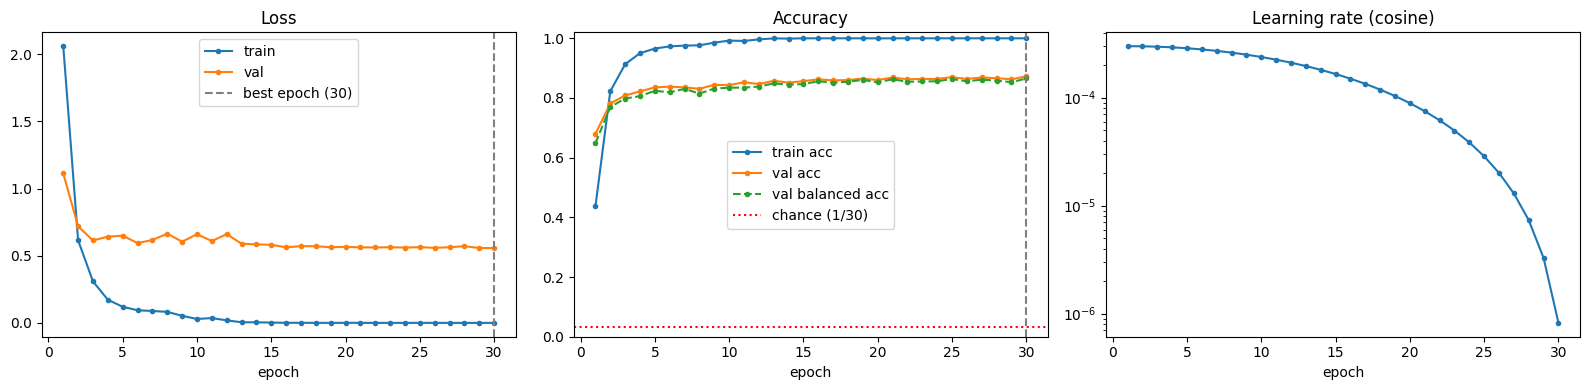

Best epoch: 30 | val acc 0.872 | val balanced acc 0.865 | train acc 1.000
Train - val accuracy gap: +0.128 at the best epoch | +0.133 on average over the last epochs
Val accuracy reached 90% of its best value at epoch 3
Lowest val loss at epoch 30 (best val acc at epoch 30)
Accuracy minus balanced accuracy on val: +0.007


In [15]:
# `history` is the DataFrame returned by Cell 12 (one row per epoch).
best_row = history.loc[history["val_acc"].idxmax()]  # the epoch with the best validation accuracy
best_epoch = int(best_row["epoch"])  # its epoch number (this is the checkpoint that was kept)

# ---------------------------------------------------------------
# 1) Plots
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4))  # three plots side by side

# Left: loss. Train and validation should both fall; validation rising while train keeps falling = overfitting.
axes[0].plot(history["epoch"], history["train_loss"], marker=".", label="train")  # training loss per epoch
axes[0].plot(history["epoch"], history["val_loss"], marker=".", label="val")  # validation loss per epoch
axes[0].axvline(best_epoch, color="gray", linestyle="--", label=f"best epoch ({best_epoch})")  # kept checkpoint
axes[0].set_title("Loss")  # plot title
axes[0].set_xlabel("epoch")  # x axis label
axes[0].legend()  # show the legend

# Middle: accuracy. Balanced accuracy (mean recall per class) shows whether rare classes are being learned.
axes[1].plot(history["epoch"], history["train_acc"], marker=".", label="train acc")  # training accuracy
axes[1].plot(history["epoch"], history["val_acc"], marker=".", label="val acc")  # validation accuracy
axes[1].plot(history["epoch"], history["val_bal_acc"], marker=".", linestyle="--", label="val balanced acc")  # per-class mean
axes[1].axvline(best_epoch, color="gray", linestyle="--")  # kept checkpoint
axes[1].axhline(1 / len(ACTIVE_IDX), color="red", linestyle=":", label=f"chance (1/{len(ACTIVE_IDX)})")  # random guessing level
axes[1].set_ylim(0, 1.02)  # accuracy lives between 0 and 1
axes[1].set_title("Accuracy")  # plot title
axes[1].set_xlabel("epoch")  # x axis label
axes[1].legend()  # show the legend

# Right: learning rate, to confirm the scheduler did what we expected.
axes[2].plot(history["epoch"], history["lr"], marker=".")  # learning rate at the start of each epoch
axes[2].set_title(f"Learning rate ({SCHEDULER})")  # plot title
axes[2].set_xlabel("epoch")  # x axis label
axes[2].set_yscale("log")  # the rate changes by orders of magnitude, a log axis shows it better

plt.tight_layout()  # avoid overlapping labels
plt.show()  # draw the figure

# ---------------------------------------------------------------
# 2) Numeric diagnostics
# ---------------------------------------------------------------
gap_best = best_row["train_acc"] - best_row["val_acc"]  # train minus validation accuracy at the best epoch
last = history.tail(3)  # the last (up to) three epochs
gap_last = (last["train_acc"] - last["val_acc"]).mean()  # average gap at the end of training
first_good = history.loc[history["val_acc"] >= 0.9 * best_row["val_acc"], "epoch"].min()  # first epoch near the best
min_loss_epoch = int(history.loc[history["val_loss"].idxmin(), "epoch"])  # epoch with the lowest validation loss

print(f"Best epoch: {best_epoch} | val acc {best_row['val_acc']:.3f} | val balanced acc {best_row['val_bal_acc']:.3f} | train acc {best_row['train_acc']:.3f}")  # headline
print(f"Train - val accuracy gap: {gap_best:+.3f} at the best epoch | {gap_last:+.3f} on average over the last epochs")  # gap
print(f"Val accuracy reached 90% of its best value at epoch {int(first_good)}")  # how fast it learned
print(f"Lowest val loss at epoch {min_loss_epoch} (best val acc at epoch {best_epoch})")  # loss vs accuracy optimum
print(f"Accuracy minus balanced accuracy on val: {best_row['val_acc'] - best_row['val_bal_acc']:+.3f}")  # imbalance effect

# ---------------------------------------------------------------
# 3) Reading the curves (hints, not proof)
# ---------------------------------------------------------------
# Careful: train metrics are averaged DURING the epoch while the weights are still improving, and
# validation is measured at the END of it. So validation being equal to or above train in the first
# epochs is normal and is NOT by itself a leakage sign. What points to leakage in a random split is
# validation accuracy that is very high, reached fast, with a tiny gap at the end.
if best_row["val_acc"] > 0.9 and first_good <= 3 and abs(gap_last) < 0.03:  # high, fast, and no gap
    print("\nHint: very high validation accuracy reached early, with almost no train/val gap. "
          "This is consistent with leakage from the random split (near-identical frames of the same plate on both sides). "
          "It does not prove it: compare with the group-based split (optional cell B) and the kNN baseline (optional cell A).")  # leakage hint
if history["val_loss"].iloc[-1] > 1.2 * history["val_loss"].min():  # validation loss climbed back up
    print("\nHint: validation loss rose well above its minimum, a sign of overfitting. "
          "Early stopping and the best-checkpoint restore already protect the final model.")  # overfitting hint

## 14 - Test set evaluation

Checkpoint: run round1_no_weights | epoch 30 | val acc 0.8724

Test samples: 815
Top-1 accuracy: 0.8810
Top-3 accuracy: 0.9607
Balanced accuracy (mean per-class recall): 0.8665

By kind of the true label:
             n    top1    top3  chance
is_letter                             
digits     361  0.8864  0.9584    0.10
letters    454  0.8767  0.9626    0.05

Per-class accuracy (worst first). With few test samples a class is noisy, look at n_test:
       n_test  n_correct    acc
label                          
B          28         15  0.536
6          20         13  0.650
S          21         14  0.667
8          22         15  0.682
Q          10          7  0.700
5          33         24  0.727
9          21         16  0.762
A          15         12  0.800
3          20         16  0.800
D          41         33  0.805
V          11          9  0.818
G          26         22  0.846
R          28         24  0.857
P          35         31  0.886
F          18         16  0.889
N   

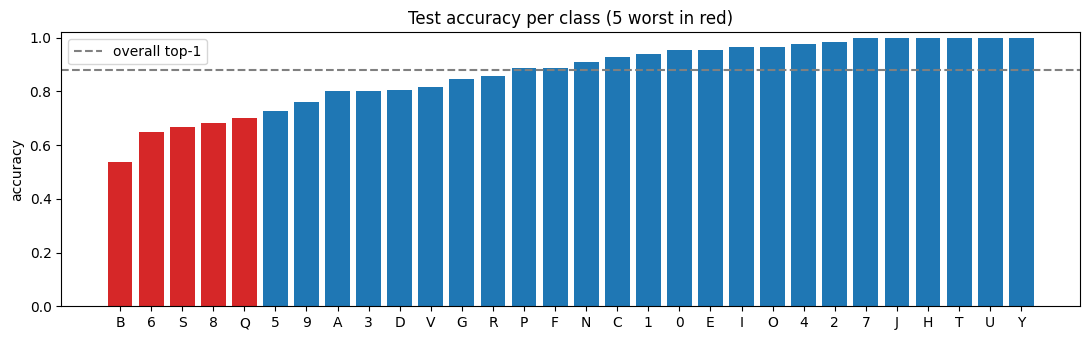

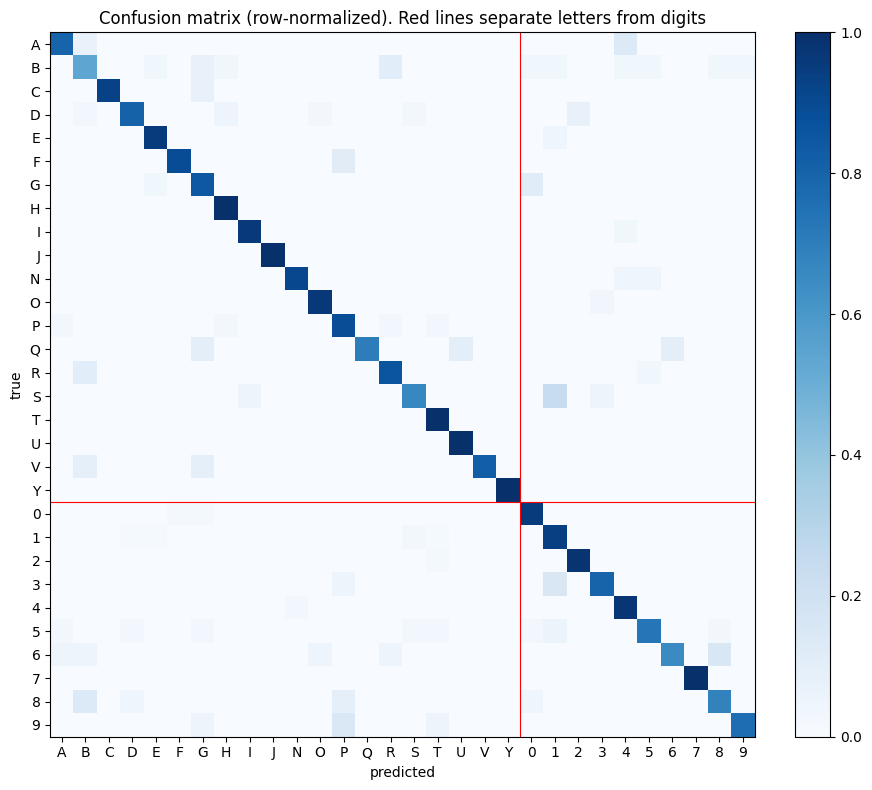


Total errors: 97 of 815

Most frequent confusions:
true pred  count  pct_of_true  cross_type
   S    1      5        0.238        True
   B    R      3        0.107       False
   D    2      3        0.073        True
   R    B      3        0.107       False
   G    0      3        0.115        True
   8    B      3        0.136        True
   6    8      3        0.150       False
   9    P      3        0.143        True
   3    1      3        0.150       False
   D    H      2        0.049       False
   A    4      2        0.133        True
   8    P      2        0.091        True

Cross-type errors (letter <-> digit): 57 = 58.8% of all errors
Upper bound for what a type mask could win: +7.0% accuracy (an upper bound: some of these samples would still be wrong inside the right type)

Cross-type pairs:
true pred  count  pct_of_true  cross_type
   S    1      5        0.238        True
   D    2      3        0.073        True
   G    0      3        0.115        True
   8    B

In [16]:
# ---------------------------------------------------------------
# 1) Load the best checkpoint into a fresh model
# ---------------------------------------------------------------
ckpt = torch.load(best_path, map_location=DEVICE)  # read the checkpoint saved by Cell 12
eval_model, _ = build_model(pretrained=False)  # same architecture; no need to download ImageNet weights again
eval_model.load_state_dict(ckpt["model_state_dict"])  # put the trained weights in
eval_model = eval_model.to(DEVICE).eval()  # to the GPU, and eval mode (BatchNorm frozen)
print(f"Checkpoint: run {ckpt['run_name']} | epoch {ckpt['epoch']} | val acc {ckpt['val_acc']:.4f}")  # what we are evaluating

# ---------------------------------------------------------------
# 2) Predict the whole test set (probabilities over the active classes)
# ---------------------------------------------------------------
@torch.no_grad()  # no gradients needed while predicting
def predict_probs(net, loader):
    """Return an (N, 36) array of probabilities. Inactive classes get exactly 0."""
    net.eval()  # make sure BatchNorm is frozen
    out = []  # one tensor per batch
    for xb, _ in loader:  # labels are ignored here
        logits = net(xb.to(DEVICE))  # raw scores
        out.append(mask_inactive(logits).softmax(dim=1).cpu())  # mask, then convert to probabilities
    return torch.cat(out).numpy()  # one big numpy array


TEST_PROBS = predict_probs(eval_model, test_loader)  # kept for later cells (error analysis)

# One row per test sample, in the same order as idx_test (the loader does not shuffle).
test_df = df.loc[idx_test, ["crop_id", "group_id", "label", "is_letter", "orig_h", "y"]].reset_index(drop=True)  # metadata
assert len(test_df) == len(TEST_PROBS)  # one prediction per test sample
assert (test_ds.y.numpy() == test_df["y"].to_numpy()).all(), "loader order does not match idx_test"  # alignment check

test_df["pred"] = TEST_PROBS.argmax(axis=1)  # most probable class
test_df["conf"] = TEST_PROBS.max(axis=1)  # its probability (the model's confidence)
top3 = np.argsort(-TEST_PROBS, axis=1)[:, :3]  # the 3 most probable classes of each sample
test_df["top3_ok"] = (top3 == test_df["y"].to_numpy()[:, None]).any(axis=1)  # true class among the top 3?
test_df["correct"] = test_df["pred"] == test_df["y"]  # top-1 correct?
test_df["pred_label"] = test_df["pred"].map(IDX_TO_CLASS)  # predicted class as a letter/digit

# ---------------------------------------------------------------
# 3) Overall metrics
# ---------------------------------------------------------------
per_class = (  # one row per true class
    test_df.groupby("label")["correct"].agg(n_test="size", n_correct="sum", acc="mean")  # counts and recall
    .sort_values("acc")  # worst classes first
)
print(f"\nTest samples: {len(test_df)}")  # size of the test set
print(f"Top-1 accuracy: {test_df['correct'].mean():.4f}")  # overall accuracy
print(f"Top-3 accuracy: {test_df['top3_ok'].mean():.4f}")  # true class among the 3 best guesses
print(f"Balanced accuracy (mean per-class recall): {per_class['acc'].mean():.4f}")  # not dominated by frequent classes

# ---------------------------------------------------------------
# 4) Letters and digits reported separately (grouped by the TRUE label's type)
# ---------------------------------------------------------------
# Just a split of the report: the model never sees the type. Chance differs: 1/20 vs 1/10.
n_active_letters = sum(c.isalpha() for c in ACTIVE_CLASSES)  # number of active letter classes
n_active_digits = len(ACTIVE_CLASSES) - n_active_letters  # number of active digit classes
by_kind = test_df.groupby("is_letter").agg(n=("correct", "size"), top1=("correct", "mean"), top3=("top3_ok", "mean"))  # metrics
by_kind.index = by_kind.index.map({True: "letters", False: "digits"})  # readable names
by_kind["chance"] = pd.Series({"letters": 1 / n_active_letters, "digits": 1 / n_active_digits})  # random-guess level
print("\nBy kind of the true label:")  # section title
print(by_kind.round(4).to_string())  # table

# ---------------------------------------------------------------
# 5) Per-class accuracy
# ---------------------------------------------------------------
print("\nPer-class accuracy (worst first). With few test samples a class is noisy, look at n_test:")  # note on noise
print(per_class.assign(acc=per_class["acc"].round(3)).to_string())  # full table

order = per_class.index.tolist()  # classes sorted from worst to best
colors = ["tab:red" if i < 5 else "tab:blue" for i in range(len(order))]  # highlight the 5 worst
plt.figure(figsize=(11, 3.5))  # wide, short figure
plt.bar(order, per_class["acc"].values, color=colors)  # one bar per class
plt.axhline(test_df["correct"].mean(), color="gray", linestyle="--", label="overall top-1")  # reference line
plt.title("Test accuracy per class (5 worst in red)")  # title
plt.ylabel("accuracy")  # y label
plt.ylim(0, 1.02)  # accuracy is between 0 and 1
plt.legend()  # show the reference line label
plt.tight_layout()  # avoid overlapping
plt.show()  # draw it

# ---------------------------------------------------------------
# 6) Confusion matrix 30x30 (rows: true class, columns: predicted class)
# ---------------------------------------------------------------
cm = confusion_matrix(test_df["y"], test_df["pred"], labels=ACTIVE_IDX)  # raw counts, active classes only
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)  # each row sums to 1 (fraction of that true class)
names = [IDX_TO_CLASS[i] for i in ACTIVE_IDX]  # tick labels, letters first then digits

fig, ax = plt.subplots(figsize=(9, 8))  # a big square-ish figure
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)  # darker = larger fraction
ax.set_xticks(range(len(names)))  # one tick per class (x)
ax.set_xticklabels(names)  # predicted class names
ax.set_yticks(range(len(names)))  # one tick per class (y)
ax.set_yticklabels(names)  # true class names
ax.axhline(n_active_letters - 0.5, color="red", linewidth=0.8)  # boundary between letters and digits (rows)
ax.axvline(n_active_letters - 0.5, color="red", linewidth=0.8)  # boundary between letters and digits (columns)
ax.set_xlabel("predicted")  # x label
ax.set_ylabel("true")  # y label
ax.set_title("Confusion matrix (row-normalized). Red lines separate letters from digits")  # title
fig.colorbar(im, ax=ax, fraction=0.046)  # color scale
plt.tight_layout()  # avoid overlapping
plt.show()  # draw it

# ---------------------------------------------------------------
# 7) Most frequent confusions and cross-type confusions
# ---------------------------------------------------------------
rows = []  # one dict per (true, predicted) wrong pair
for i, t in enumerate(ACTIVE_IDX):  # true class
    for j, p in enumerate(ACTIVE_IDX):  # predicted class
        if i != j and cm[i, j] > 0:  # only mistakes that actually happened
            rows.append({
                "true": IDX_TO_CLASS[t], "pred": IDX_TO_CLASS[p],  # the pair as letters/digits
                "count": int(cm[i, j]),  # how many times
                "pct_of_true": round(cm[i, j] / cm[i].sum(), 3),  # share of that true class
                "cross_type": (t < 26) != (p < 26),  # letter<->digit mix-up?
            })
conf_df = pd.DataFrame(rows).sort_values("count", ascending=False) if rows else pd.DataFrame()  # all mistakes

n_errors = int((~test_df["correct"]).sum())  # total wrong predictions
print(f"\nTotal errors: {n_errors} of {len(test_df)}")  # headline
if len(conf_df):  # skip if the model made no mistakes
    print("\nMost frequent confusions:")  # section title
    print(conf_df.head(12).to_string(index=False))  # top 12 pairs

    n_cross = int(conf_df.loc[conf_df["cross_type"], "count"].sum())  # errors that mix letter and digit
    print(f"\nCross-type errors (letter <-> digit): {n_cross} = {n_cross / max(n_errors, 1):.1%} of all errors")  # share of errors
    print(f"Upper bound for what a type mask could win: +{n_cross / len(test_df):.1%} accuracy "
          "(an upper bound: some of these samples would still be wrong inside the right type)")  # diagnostic only
    if conf_df["cross_type"].any():  # list the pairs if any exist
        print("\nCross-type pairs:")  # section title
        print(conf_df[conf_df["cross_type"]].head(8).to_string(index=False))  # most frequent ones

# ---------------------------------------------------------------
# 8) Save the predictions and remind ourselves how to read the number
# ---------------------------------------------------------------
pred_path = OUTPUT_DIR / f"{RUN_NAME}_test_predictions.csv"  # where the per-sample results go
test_df.to_csv(pred_path, index=False)  # used by the next cells and for later comparisons
print(f"\nSaved {pred_path}")  # confirm the location
print("\nReminder: this split is random (no group separation). Near-identical frames of the same plate "
      "are in train and test, so treat these numbers as a ceiling, not as real-world performance.")  # leakage caveat